Travel App Customer & Booking — Complete EDA

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt






In [2]:
pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",100)
df=pd.read_csv("C:/Users/brind/Downloads/travelapp_dataset.csv")
print("dataset loaded successfully")
print("shape:",df.shape)

dataset loaded successfully
shape: (100000, 21)


In [3]:
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nDataset Information:")
df.info()


Column names:
['Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Destination', 'Travel_Type', 'Package_Type', 'Booking_Count', 'Booking_Amount', 'Trip_Duration', 'Customer_Rating', 'Customer_Likes', 'Reviews', 'Hotel_Rating', 'Transport_Mode', 'Payment_Method', 'Booking_Status', 'Cancellation_Count', 'App_Usage', 'Loyalty_Member']

Data types:
Customer_ID            object
Customer_Name          object
Age                   float64
Gender                 object
City                   object
Destination            object
Travel_Type            object
Package_Type           object
Booking_Count           int64
Booking_Amount         object
Trip_Duration           int64
Customer_Rating       float64
Customer_Likes         object
Reviews               float64
Hotel_Rating          float64
Transport_Mode         object
Payment_Method         object
Booking_Status         object
Cancellation_Count      int64
App_Usage              object
Loyalty_Member         object
dtype: object



In [10]:
print("\nStatistical summary:")
display(df.describe(include="all").T)
numerical_cols=df.select_dtypes(include=np.number).columns.tolist()
categorical_cols=df.select_dtypes(include="object").columns.tolist()
print("numerical col:")
print(numerical_cols)
print("\nCategrical columns")
print(categorical_cols)


Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,100000,100000,C10001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,100000,100000,Customer_1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,99500.0,NaN,NaN,NaN,41.441367,13.926745,8.0,29.0,41.0,53.0,105.0
Gender,99700,2,Female,50003,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,99437,19,Bengaluru,13723,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination,99383,22,Kashmir,6759,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Travel_Type,99547,6,Business,20110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Package_Type,100000,4,Standard,40061,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Booking_Count,100000.0,NaN,NaN,NaN,4.50687,2.291389,1.0,3.0,5.0,7.0,8.0
Booking_Amount,99300,80052,-500,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN


numerical col:
['Age', 'Booking_Count', 'Trip_Duration', 'Customer_Rating', 'Reviews', 'Hotel_Rating', 'Cancellation_Count']

Categrical columns
['Customer_ID', 'Customer_Name', 'Gender', 'City', 'Destination', 'Travel_Type', 'Package_Type', 'Booking_Amount', 'Customer_Likes', 'Transport_Mode', 'Payment_Method', 'Booking_Status', 'App_Usage', 'Loyalty_Member']


Data quality checking

In [12]:
print("contains missing values:",df.isnull().values.any())
missing_count=df.isnull().sum()
print("\nMissing values:")
display(missing_count[missing_count>0].sort_values(ascending=False))
missing_percentage=(df.isnull().mean()*100).sort_values(ascending=False)
print("\nMissing-value percentage")
display(missing_percentage[missing_percentage>0])

contains missing values: True

Missing values:


Booking_Amount     700
Destination        617
City               563
Age                500
Customer_Rating    500
Travel_Type        453
Hotel_Rating       450
Customer_Likes     450
Payment_Method     406
Reviews            350
App_Usage          350
Gender             300
dtype: int64


Missing-value percentage


Booking_Amount     0.700
Destination        0.617
City               0.563
Age                0.500
Customer_Rating    0.500
Travel_Type        0.453
Customer_Likes     0.450
Hotel_Rating       0.450
Payment_Method     0.406
App_Usage          0.350
Reviews            0.350
Gender             0.300
dtype: float64

In [13]:
print("\nDuplicate records exist:",df.duplicated().any())
print("Duplicate record count:",df.duplicated().sum())
print("\nCity values:")
print(sorted(df["City"].dropna().astype(str).unique()))






Duplicate records exist: False
Duplicate record count: 0

City values:
['BENGALURU', 'Bangalore', 'Bengaluru', 'CHENNAI', 'Chennai', 'Coimbatore', 'Delhi', 'Hyderabad', 'Kochi', 'Kolkata', 'Madurai', 'Mumbai', 'Nagercoil', 'Pune', 'Salem', 'Trichy', 'bengaluru', 'chennai', 'unknown']


In [18]:
print("\nDestination values:")
print(sorted(df["Destination"].dropna().astype(str).unique()))
print("\nInvalid age count:",((df["Age"]<18)|(df["Age"]>100)).sum())
print("invalid age")
display(df.loc[(df["Age"]<18)|(df["Age"]>100),["Customer_ID","Age"]].head())



Destination values:
['Bali', 'DUBAI', 'Delhi', 'Dubai', 'GOA', 'Goa', 'Hyderabad', 'Jaipur', 'Kashmir', 'Kerala', 'MUNNAR', 'Maldives', 'Manali', 'Mumbai', 'Munnar', 'Ooty', 'Singapore', 'Thailand', 'dubai', 'goa', 'munnar', 'unknown']

Invalid age count: 76
invalid age


,Customer_ID,Age
1897,C11898,8.0
2659,C12660,8.0
3182,C13183,105.0
6389,C16390,12.0
6883,C16884,12.0


Data cleaning

In [19]:

# Work on a copy so the original df remains available
clean_df = df.copy()

# ---------------------------------------------------------
# 1. Handle NA, N/A, unknown and blank values
# ---------------------------------------------------------
missing_words = ['unknown', 'Unknown', 'UNKNOWN', 'N/A', 'n/a', 'NA', 'na', '']

for col in clean_df.select_dtypes(include='object').columns:
    clean_df[col] = clean_df[col].astype('string').str.strip()
    clean_df[col] = clean_df[col].replace(missing_words, pd.NA)

# ---------------------------------------------------------
# 2. Standardize City values
# ---------------------------------------------------------
clean_df['City'] = clean_df['City'].str.strip().str.title()

# Correct known spelling variation
clean_df['City'] = clean_df['City'].replace({
    'Bangalore': 'Bengaluru'
})

# ---------------------------------------------------------
# 3. Standardize Destination values
# ---------------------------------------------------------
clean_df['Destination'] = clean_df['Destination'].str.strip().str.title()

# ---------------------------------------------------------
# 4. Convert numeric columns stored as text
# ---------------------------------------------------------
numeric_text_cols = ['Booking_Amount', 'Customer_Likes']

for col in numeric_text_cols:
    clean_df[col] = pd.to_numeric(
        clean_df[col].astype('string').str.replace(',', '', regex=False),
        errors='coerce'
    )

# Make sure these columns are numeric
numeric_cols = [
    'Age', 'Booking_Count', 'Booking_Amount', 'Trip_Duration',
    'Customer_Rating', 'Customer_Likes', 'Reviews',
    'Hotel_Rating', 'Cancellation_Count'
]

for col in numeric_cols:
    clean_df[col] = pd.to_numeric(clean_df[col], errors='coerce').astype('float64')

# ---------------------------------------------------------
# 5. Correct invalid Age values
#    Assumption: valid customer age is 18–100
# ---------------------------------------------------------
clean_df.loc[
    (clean_df['Age'] < 18) | (clean_df['Age'] > 100),
    'Age'
] = np.nan

# ---------------------------------------------------------
# 6. Correct invalid Customer_Rating values
# ---------------------------------------------------------
clean_df.loc[
    (clean_df['Customer_Rating'] < 0) | (clean_df['Customer_Rating'] > 5),
    'Customer_Rating'
] = np.nan

# ---------------------------------------------------------
# 7. Correct invalid Hotel_Rating values
# ---------------------------------------------------------
clean_df.loc[
    (clean_df['Hotel_Rating'] < 0) | (clean_df['Hotel_Rating'] > 5),
    'Hotel_Rating'
] = np.nan

# ---------------------------------------------------------
# 8. Correct invalid Booking_Amount values
#    Amount must be greater than 0
# ---------------------------------------------------------
clean_df.loc[
    clean_df['Booking_Amount'] <= 0,
    'Booking_Amount'
] = np.nan

# ---------------------------------------------------------
# 9. Correct invalid Trip_Duration values
# ---------------------------------------------------------
clean_df.loc[
    clean_df['Trip_Duration'] <= 0,
    'Trip_Duration'
] = np.nan

# ---------------------------------------------------------
# 10. Fill missing numeric values with median
# ---------------------------------------------------------
numeric_cols_to_fill = [
    'Age', 'Booking_Amount', 'Trip_Duration',
    'Customer_Rating', 'Customer_Likes',
    'Reviews', 'Hotel_Rating'
]

for col in numeric_cols_to_fill:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# ---------------------------------------------------------
# 11. Fill missing categorical values with mode
# ---------------------------------------------------------
categorical_cols_to_fill = [
    'Gender', 'City', 'Destination',
    'Travel_Type', 'Payment_Method', 'App_Usage'
]

for col in categorical_cols_to_fill:
    clean_df[col] = clean_df[col].fillna(clean_df[col].mode()[0])

# ---------------------------------------------------------
# 12. Remove duplicate records
# ---------------------------------------------------------
before_duplicates = len(clean_df)
clean_df = clean_df.drop_duplicates()
removed_duplicates = before_duplicates - len(clean_df)

print("Duplicate records removed:", removed_duplicates)
print("Rows after cleaning:", len(clean_df))


Duplicate records removed: 0
Rows after cleaning: 100000


In [20]:
print("Shape after cleaning:", clean_df.shape)

print("\nMissing values after cleaning:")
display(clean_df.isnull().sum())

print("\nDuplicate records after cleaning:", clean_df.duplicated().sum())

print("\nData types after cleaning:")
print(clean_df.dtypes)

print("\nAge range:", clean_df['Age'].min(), "to", clean_df['Age'].max())
print("Customer Rating range:", clean_df['Customer_Rating'].min(), "to", clean_df['Customer_Rating'].max())
print("Hotel Rating range:", clean_df['Hotel_Rating'].min(), "to", clean_df['Hotel_Rating'].max())
print("Booking Amount range:", clean_df['Booking_Amount'].min(), "to", clean_df['Booking_Amount'].max())
print("Trip Duration range:", clean_df['Trip_Duration'].min(), "to", clean_df['Trip_Duration'].max())

# Save cleaned dataset
clean_df.to_csv("cleaned_travel_dataset.csv", index=False)
print("\nCleaned dataset saved as cleaned_travel_dataset.csv")


Shape after cleaning: (100000, 21)

Missing values after cleaning:


Customer_ID           0
Customer_Name         0
Age                   0
Gender                0
City                  0
Destination           0
Travel_Type           0
Package_Type          0
Booking_Count         0
Booking_Amount        0
Trip_Duration         0
Customer_Rating       0
Customer_Likes        0
Reviews               0
Hotel_Rating          0
Transport_Mode        0
Payment_Method        0
Booking_Status        0
Cancellation_Count    0
App_Usage             0
Loyalty_Member        0
dtype: int64


Duplicate records after cleaning: 0

Data types after cleaning:
Customer_ID           string[python]
Customer_Name         string[python]
Age                          float64
Gender                string[python]
City                  string[python]
Destination           string[python]
Travel_Type           string[python]
Package_Type          string[python]
Booking_Count                float64
Booking_Amount               float64
Trip_Duration                float64
Customer_Rating              float64
Customer_Likes               float64
Reviews                      float64
Hotel_Rating                 float64
Transport_Mode        string[python]
Payment_Method        string[python]
Booking_Status        string[python]
Cancellation_Count           float64
App_Usage             string[python]
Loyalty_Member        string[python]
dtype: object

Age range: 18.0 to 90.0
Customer Rating range: 0.0 to 5.0
Hotel Rating range: 2.5 to 5.0
Booking Amount range: 3750.0 to 607365.0
Trip Duration

customer analysis

In [21]:
print("Average customer age:", clean_df['Age'].mean())
print("Minimum age:", clean_df['Age'].min())
print("Maximum age:", clean_df['Age'].max())

print("\nAverage booking amount:", clean_df['Booking_Amount'].mean())
print("Minimum booking amount:", clean_df['Booking_Amount'].min())
print("Maximum booking amount:", clean_df['Booking_Amount'].max())

print("\nAverage trip duration:", clean_df['Trip_Duration'].mean())
print("Average customer rating:", clean_df['Customer_Rating'].mean())
print("Median customer rating:", clean_df['Customer_Rating'].median())

print("\nAverage booking count:", clean_df['Booking_Count'].mean())
print("Average cancellation count:", clean_df['Cancellation_Count'].mean())


Average customer age: 41.43669
Minimum age: 18.0
Maximum age: 90.0

Average booking amount: 107063.41153
Minimum booking amount: 3750.0
Maximum booking amount: 607365.0

Average trip duration: 8.0299
Average customer rating: 3.7471189999999996
Median customer rating: 3.7

Average booking count: 4.50687
Average cancellation count: 1.50472


destination analysis

In [22]:
# 1. Number of bookings for each destination
destination_bookings = clean_df.groupby('Destination').size().sort_values(ascending=False)
print("Bookings by destination:")
display(destination_bookings)

# 2. Most popular destination
print("\nMost popular destination:", destination_bookings.idxmax())

# 3. Top 10 destinations
print("\nTop 10 destinations:")
display(destination_bookings.head(10))

# 4. Average booking amount
avg_booking_destination = clean_df.groupby('Destination')['Booking_Amount'].mean().sort_values(ascending=False)
print("\nAverage booking amount by destination:")
display(avg_booking_destination)

# 5. Average trip duration
print("\nAverage trip duration by destination:")
display(clean_df.groupby('Destination')['Trip_Duration'].mean().sort_values(ascending=False))

# 6. Average customer rating
avg_rating_destination = clean_df.groupby('Destination')['Customer_Rating'].mean().sort_values(ascending=False)
print("\nAverage customer rating by destination:")
display(avg_rating_destination)

# 7. Average likes
print("\nAverage likes by destination:")
display(clean_df.groupby('Destination')['Customer_Likes'].mean().sort_values(ascending=False))

# 8. Destination with highest average booking amount
print("\nHighest average booking amount destination:", avg_booking_destination.idxmax())
print("Average amount:", avg_booking_destination.max())

# 9. Destination with highest average rating
print("\nHighest average rating destination:", avg_rating_destination.idxmax())
print("Average rating:", avg_rating_destination.max())


Bookings by destination:


Destination
Kashmir      7407
Ooty         6737
Munnar       6693
Manali       6682
Hyderabad    6652
Thailand     6636
Mumbai       6596
Jaipur       6593
Maldives     6592
Kerala       6589
Dubai        6578
Singapore    6578
Goa          6571
Delhi        6554
Bali         6542
dtype: int64


Most popular destination: Kashmir

Top 10 destinations:


Destination
Kashmir      7407
Ooty         6737
Munnar       6693
Manali       6682
Hyderabad    6652
Thailand     6636
Mumbai       6596
Jaipur       6593
Maldives     6592
Kerala       6589
dtype: int64


Average booking amount by destination:


...


Average customer rating by destination:


Destination
Goa          3.761802
Munnar       3.760780
Kerala       3.757960
Mumbai       3.757277
Thailand     3.756254
Hyderabad    3.750135
Jaipur       3.748218
Singapore    3.746777
Bali         3.741975
Delhi        3.740998
Maldives     3.740746
Ooty         3.738415
Kashmir      3.738113
Manali       3.736112
Dubai        3.732320
Name: Customer_Rating, dtype: float64


Average likes by destination:


Destination
Goa          2542.426876
Delhi        2539.939274
Kashmir      2534.210747
Dubai        2528.512770
Munnar       2528.275811
Singapore    2528.201885
Thailand     2512.789180
Maldives     2512.617870
Manali       2508.193954
Jaipur       2506.089185
Ooty         2505.661422
Hyderabad    2504.737673
Bali         2492.103485
Mumbai       2485.204063
Kerala       2483.850660
Name: Customer_Likes, dtype: float64


Highest average booking amount destination: Hyderabad
Average amount: 109444.05464521948

Highest average rating destination: Goa
Average rating: 3.7618018566428244


Travel & Package Analysis

In [24]:
# Travel type analysis
travel_customers = clean_df.groupby('Travel_Type')['Customer_ID'].nunique().sort_values(ascending=False)

print("Customers by travel type:")
display(travel_customers)

print("\nAverage booking amount by travel type:")
display(clean_df.groupby('Travel_Type')['Booking_Amount'].mean().sort_values(ascending=False))

print("\nAverage trip duration by travel type:")
display(clean_df.groupby('Travel_Type')['Trip_Duration'].mean().sort_values(ascending=False))

print("\nAverage customer rating by travel type:")
display(clean_df.groupby('Travel_Type')['Customer_Rating'].mean().sort_values(ascending=False))

# Package analysis
package_customers = clean_df.groupby('Package_Type')['Customer_ID'].nunique().sort_values(ascending=False)

print("\nCustomers by package type:")
display(package_customers)

avg_package_amount = clean_df.groupby('Package_Type')['Booking_Amount'].mean().sort_values(ascending=False)

print("\nAverage booking amount by package:")
display(avg_package_amount)

print("\nMost popular package type:", package_customers.idxmax())
print("Package customer count:", package_customers.max())

print("\nPackage with highest average booking amount:", avg_package_amount.idxmax())
print("Average amount:", avg_package_amount.max())


Customers by travel type:


Travel_Type
Business    20609
Couple      19941
Solo        19872
Family      19858
Friends     19720
Name: Customer_ID, dtype: int64


Average booking amount by travel type:


Travel_Type
Solo        108241.577395
Family      107542.630023
Business    107065.289534
Couple      106323.789203
Friends     106139.540948
Name: Booking_Amount, dtype: float64


Average trip duration by travel type:


...


Customers by package type:


Package_Type
Standard    40061
Premium     25024
Budget      24847
Luxury      10068
Name: Customer_ID, dtype: int64


Average booking amount by package:


Package_Type
Luxury      249511.420242
Premium     150765.224305
Standard     84076.941614
Budget       42391.630499
Name: Booking_Amount, dtype: float64


Most popular package type: Standard
Package customer count: 40061

Package with highest average booking amount: Luxury
Average amount: 249511.420242352


Booking Analysis

In [25]:
# 1. Count bookings by status
status_counts = clean_df['Booking_Status'].value_counts()
print("Bookings by status:")
display(status_counts)

# 2–4. Booking status percentages
status_percentage = clean_df['Booking_Status'].value_counts(normalize=True).mul(100).round(2)

print("Completed percentage:", status_percentage.get('Completed', 0), "%")
print("Cancelled percentage:", status_percentage.get('Cancelled', 0), "%")
print("Pending percentage:", status_percentage.get('Pending', 0), "%")

# 5. Total booking amount
print("\nTotal booking amount:", clean_df['Booking_Amount'].sum())

# 6. Average booking amount
print("Average booking amount:", clean_df['Booking_Amount'].mean())

# 7. Average booking count by booking status
print("\nAverage booking count by status:")
display(clean_df.groupby('Booking_Status')['Booking_Count'].mean().sort_values(ascending=False))

# 8. Average cancellation count by status
print("\nAverage cancellation count by status:")
display(clean_df.groupby('Booking_Status')['Cancellation_Count'].mean().sort_values(ascending=False))

# 9. Transport mode with highest bookings
transport_counts = clean_df['Transport_Mode'].value_counts()
print("\nBookings by transport mode:")
display(transport_counts)
print("Most commonly used transport mode:", transport_counts.idxmax())

# 10. Most common payment method
payment_counts = clean_df['Payment_Method'].value_counts()
print("\nPayment method counts:")
display(payment_counts)
print("Most commonly used payment method:", payment_counts.idxmax())


Bookings by status:


Booking_Status
Completed    82001
Cancelled    11947
Pending       6052
Name: count, dtype: Int64

Completed percentage: 82.0 %
Cancelled percentage: 11.95 %
Pending percentage: 6.05 %

Total booking amount: 10706341153.0
Average booking amount: 107063.41153

Average booking count by status:


Booking_Status
Completed    4.508530
Cancelled    4.505399
Pending      4.487277
Name: Booking_Count, dtype: float64


Average cancellation count by status:


...


Bookings by transport mode:


Transport_Mode
Flight    45040
Train     24945
Bus       15079
Car       14936
Name: count, dtype: Int64

Most commonly used transport mode: Flight

Payment method counts:


Payment_Method
Cash           20472
Net Banking    19987
Credit Card    19873
UPI            19866
Debit Card     19802
Name: count, dtype: Int64

Most commonly used payment method: Cash


Customer Preference & Loyalty

In [26]:
# 1. Compare loyalty and non-loyalty members
loyalty_summary = clean_df.groupby('Loyalty_Member').agg(
    Customers=('Customer_ID', 'nunique'),
    Avg_Booking_Amount=('Booking_Amount', 'mean'),
    Avg_Booking_Count=('Booking_Count', 'mean'),
    Avg_Customer_Rating=('Customer_Rating', 'mean')
).round(2)

display(loyalty_summary)

# 2. Average booking amount for loyalty members
print("Average booking amount - Loyalty Members:",
      clean_df.loc[clean_df['Loyalty_Member'] == 'Yes', 'Booking_Amount'].mean())

# 3. Average booking count for loyalty members
print("Average booking count - Loyalty Members:",
      clean_df.loc[clean_df['Loyalty_Member'] == 'Yes', 'Booking_Count'].mean())

# 4. Average customer rating for loyalty members
print("Average rating - Loyalty Members:",
      clean_df.loc[clean_df['Loyalty_Member'] == 'Yes', 'Customer_Rating'].mean())

# 5. Customers by App Usage
app_usage_counts = clean_df['App_Usage'].value_counts()
print("\nCustomers by App Usage:")
display(app_usage_counts)

# 6. Average booking amount by App Usage
print("\nAverage booking amount by App Usage:")
display(clean_df.groupby('App_Usage')['Booking_Amount'].mean().sort_values(ascending=False))

# 7. Average booking count by App Usage
print("\nAverage booking count by App Usage:")
display(clean_df.groupby('App_Usage')['Booking_Count'].mean().sort_values(ascending=False))

# 8. Most common App Usage
print("\nMost common App Usage:", app_usage_counts.idxmax())


,Customers,Avg_Booking_Amount,Avg_Booking_Count,Avg_Customer_Rating
Loyalty_Member,,,,
No,65177,107146.39,4.50,3.75
Yes,34823,106908.10,4.51,3.75


Average booking amount - Loyalty Members: 106908.10452861614
Average booking count - Loyalty Members: 4.514889584470034
Average rating - Loyalty Members: 3.74507078654912

Customers by App Usage:


App_Usage
Medium    45416
High      34590
Low       19994
Name: count, dtype: Int64


Average booking amount by App Usage:


App_Usage
Medium    107632.278800
High      106920.432553
Low       106018.596429
Name: Booking_Amount, dtype: float64


Average booking count by App Usage:


App_Usage
Medium    4.517285
High      4.511651
Low       4.474942
Name: Booking_Count, dtype: float64


Most common App Usage: Medium


Visualization

In [27]:
# 1. Customers by city
city_customers.sort_values(ascending=False).plot(kind='bar', figsize=(12,5))
plt.title('Customers by City')
plt.xlabel('City')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Bookings by destination
destination_bookings.head(15).plot(kind='bar', figsize=(12,5))
plt.title('Bookings by Destination - Top 15')
plt.xlabel('Destination')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Average booking amount by destination
avg_booking_destination.sort_values(ascending=False).plot(kind='bar', figsize=(12,5))
plt.title('Average Booking Amount by Destination')
plt.xlabel('Destination')
plt.ylabel('Average Booking Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Customers by travel type
travel_customers.sort_values(ascending=False).plot(kind='bar', figsize=(10,5))
plt.title('Customers by Travel Type')
plt.xlabel('Travel Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


NameError: name 'city_customers' is not defined

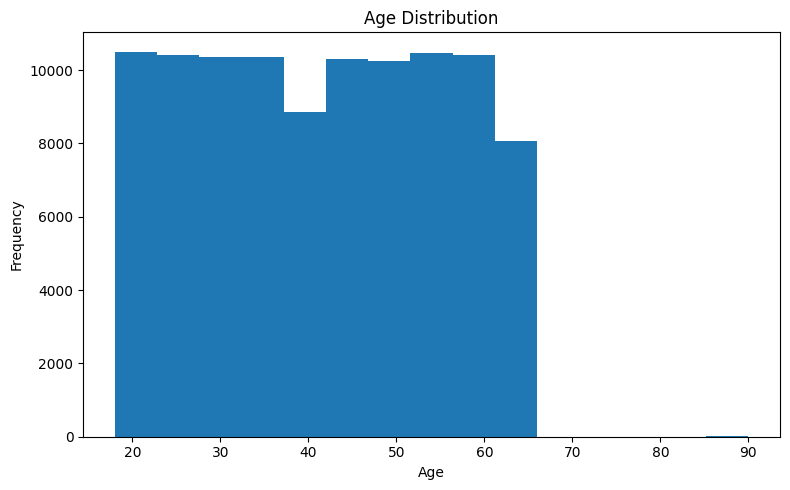

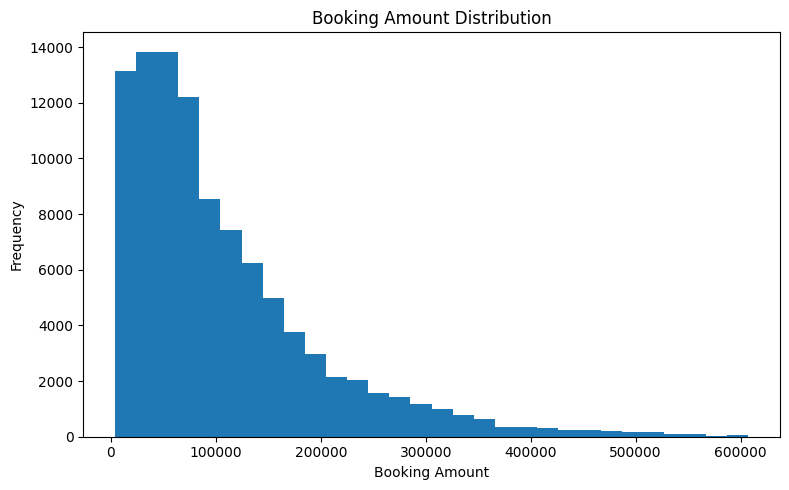

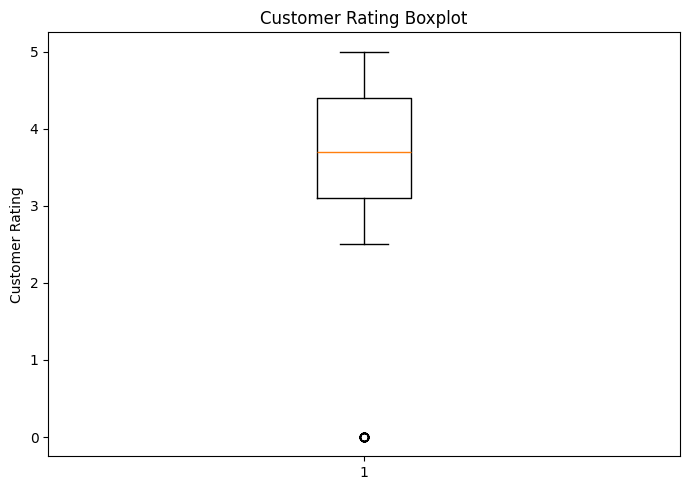

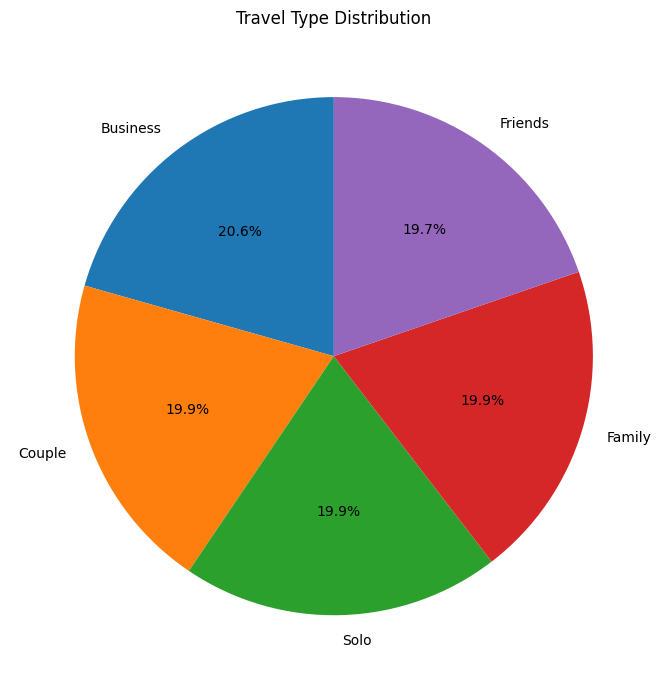

In [28]:
# 5. Histogram of Age
plt.figure(figsize=(8,5))
plt.hist(clean_df['Age'], bins=15)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# 6. Histogram of Booking Amount
plt.figure(figsize=(8,5))
plt.hist(clean_df['Booking_Amount'], bins=30)
plt.title('Booking Amount Distribution')
plt.xlabel('Booking Amount')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# 7. Boxplot for Customer Rating
plt.figure(figsize=(7,5))
plt.boxplot(clean_df['Customer_Rating'])
plt.title('Customer Rating Boxplot')
plt.ylabel('Customer Rating')
plt.tight_layout()
plt.show()

# 8. Pie chart of travel type distribution
travel_customers.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7,7),
    startangle=90
)
plt.title('Travel Type Distribution')
plt.ylabel('')
plt.tight_layout()
plt.show()


Final Business Analysis

In [30]:
# Key business findings

most_popular_destination = destination_bookings.idxmax()
most_popular_travel_type = travel_customers.idxmax()
most_popular_package = package_customers.idxmax()
highest_avg_booking_destination = avg_booking_destination.idxmax()
top_cities = city_customers.head(10)
most_common_transport = transport_counts.idxmax()
most_common_payment = payment_counts.idxmax()

print("1. Most popular destination:", most_popular_destination)
print("2. Most popular travel type:", most_popular_travel_type)
print("3. Most popular package:", most_popular_package)
print("4. Destination with highest average booking amount:", highest_avg_booking_destination)

print("\n5. Cities contributing the highest number of customers:")
display(top_cities)

print("6. Most commonly used transport mode:", most_common_transport)
print("7. Most commonly used payment method:", most_common_payment)

print("\n8. Loyalty vs Non-Loyalty:")
display(loyalty_summary)

print("\n9. Completed / Cancelled / Pending:")
booking_summary = pd.DataFrame({
    'Count': status_counts,
    'Percentage': status_percentage
}).round(2)
display(booking_summary)

print("\n10. Overall dataset summary")
print("Total unique customers:", clean_df['Customer_ID'].nunique())
print("Total records/bookings:", len(clean_df))
print("Total booking amount:", round(clean_df['Booking_Amount'].sum(), 2))
print("Average booking amount:", round(clean_df['Booking_Amount'].mean(), 2))
print("Average customer rating:", round(clean_df['Customer_Rating'].mean(), 2))
print("Average trip duration:", round(clean_df['Trip_Duration'].mean(), 2))


NameError: name 'city_customers' is not defined

## 12. Final Report Template

After running all cells, the important business findings can be written in this format:

- **Customer base:** State the total number of customers and the cities contributing the most customers.
- **Destination:** Mention the most popular destination and the destination with the highest average booking amount.
- **Travel preference:** Mention the most popular travel type and package type.
- **Bookings:** Report the Completed, Cancelled, and Pending percentages.
- **Transport & payment:** Report the most-used transport mode and payment method.
- **Loyalty:** Compare loyalty and non-loyalty members using average booking amount, booking count, and rating.
- **App usage:** Report the most common app-usage level and compare booking behavior.
- **Data quality:** Mention that missing, duplicate, inconsistent, and invalid values were checked and cleaned.
- **Output file:** `cleaned_travel_dataset.csv`
